In [2]:
from pipeline_pre_ADI.pre_process.centering import *
from pipeline_pre_ADI.pre_process.pre_processing import *
from pipeline_pre_ADI.pre_process.plot_pre_processing import *

#org
import shutil 
import torch
import numpy as np
import warnings
import os, re, glob
import pandas as pd
from copy import deepcopy
from collections import Counter
from pathlib import Path
import time
import gc
from typing import Optional, Tuple, Sequence
import pickle 
import json

# scientific libraries
from photutils.aperture import aperture_photometry, CircularAperture, RectangularAperture
from scipy.ndimage import gaussian_filter, shift, map_coordinates, fourier_shift
from skimage.registration import phase_cross_correlation
from applefy.utils.positions import center_subpixel
from numpy.fft import fftn, ifftn
from scipy.optimize import curve_fit
from scipy import ndimage as ndi
from scipy import signal

# images
# import utils.plot_pre_processing as plot
# importlib.reload(plot)
# from utils.plot_pre_processing import *
#images
import matplotlib.pyplot as plt
import tifffile as tiff
from photutils.aperture import CircularAperture
mpl.rcParams["hatch.linewidth"] = 0.5  # previous pdf hatch linewidth
plt.close('all')



from pathlib import Path
root_dir = Path(".")
print(root_dir)

/home/aosimul/noah/env_hci/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


.


# Test with peak intensity

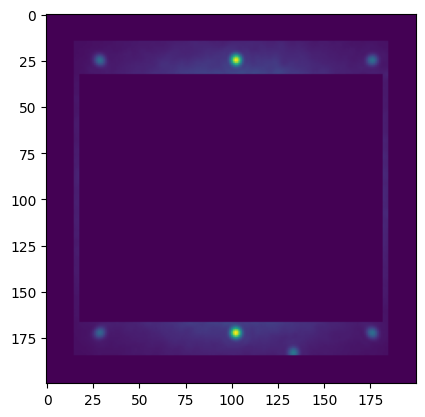

In [33]:
img = np.load('/home/aosimul/noah/data/ghost_images/10_15_20ws/int_5ro_10ws_1.npy')
img_file = '/home/aosimul/noah/data/ghost_images/phase_screens_SLM/8_24/pred_5ro_20ws_coro_2026-08-25T14-15-43.791_0.tif'
img = tiff.imread(glob.glob(img_file), 
                        key=slice(0,9978) 
                        )

zoom = rect_mask(img)
mean = np.mean(zoom, axis = (0))
plt.imshow(mean)

In [34]:
peak = np.unravel_index(np.argmax(mean, axis=None), mean.shape)
peak

(np.int64(172), np.int64(102))

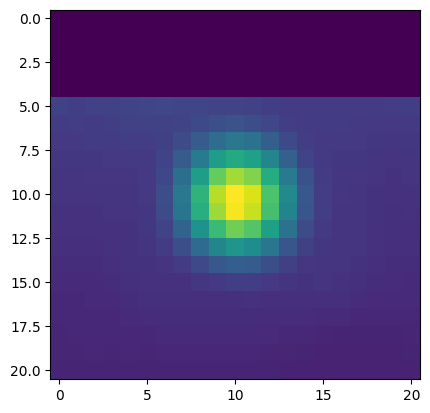

In [35]:
satellite_speckle = zoom_to_peak(mean, radius = 10)
plt.imshow(satellite_speckle)

In [43]:
def satellite_psf(img_file, radius = 5, output_path= None, filename= None):
    img = tiff.imread(glob.glob(f"{img_file}"), 
                        key=slice(0,9978) 
                        )

    zoom = rect_mask(img)
    aligned_stack = align_stack(zoom)

    mean = np.mean(aligned_stack, axis = (0))
    satellite_speckle = zoom_to_peak(mean, radius = radius)
    satellite_speckle = satellite_speckle - np.min(zoom)
    if filename is not None:
        np.save(output_path + filename, satellite_speckle)
    return satellite_speckle






    

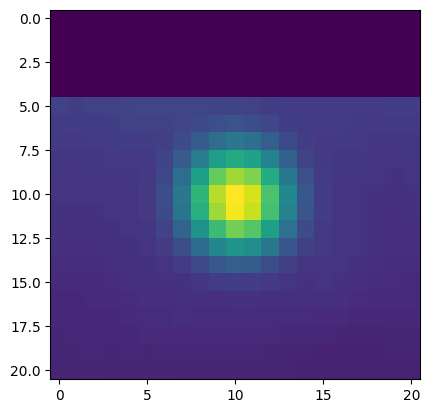

In [37]:
stacked_satellite_speckle = satellite_psf('/home/aosimul/noah/data/ghost_images/phase_screens_SLM/8_24/pred_5ro_20ws_coro_2026-08-25T14-15-43.791_0.tif', radius = 10)
plt.imshow(stacked_satellite_speckle)
#np.save(output_path + filename+ '.npy', satellite_speckle)

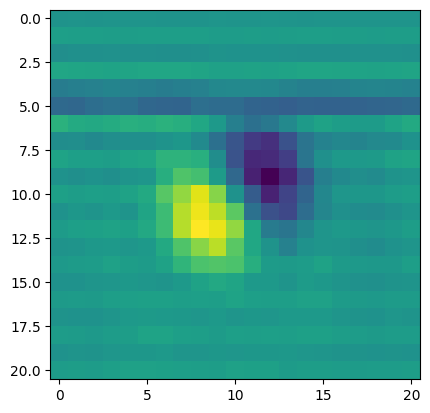

In [38]:
plt.imshow(stacked_satellite_speckle - satellite_speckle)

FWHM_x = 8.01 pix
FWHM_y = 6.71 pix
Mean FWHM = 7.36 pix 

9893.455322265625


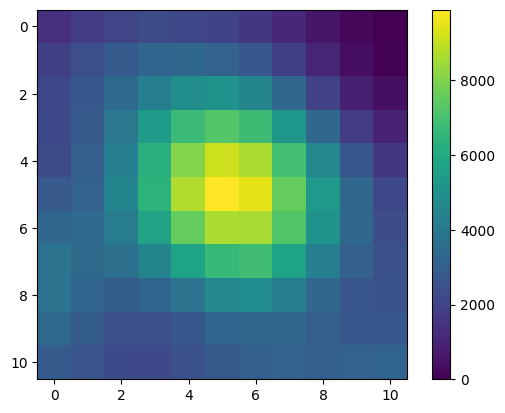

In [47]:
zoom = zoom_to_peak(satellite_speckle, radius = 5)
zoom = zoom - np.min(zoom)
plt.imshow(zoom)
calculate_fwhm(zoom)
plt.colorbar()
print(np.max(zoom))

In [ ]:
# for f in Path('/home/aosimul/noah/data/ghost_images/10_15_20ws').iterdir():
#     if f.is_file() and ".npy.npy" in f.name:
#         new_name = f.name.replace(".npy.npy", ".npy")
#         f.rename(Path('/home/aosimul/noah/data/ghost_images/10_15_20ws') / new_name)

# Try aperture photometry instead of brightest pixel

Peak value of the satellite speckle: 376951.0


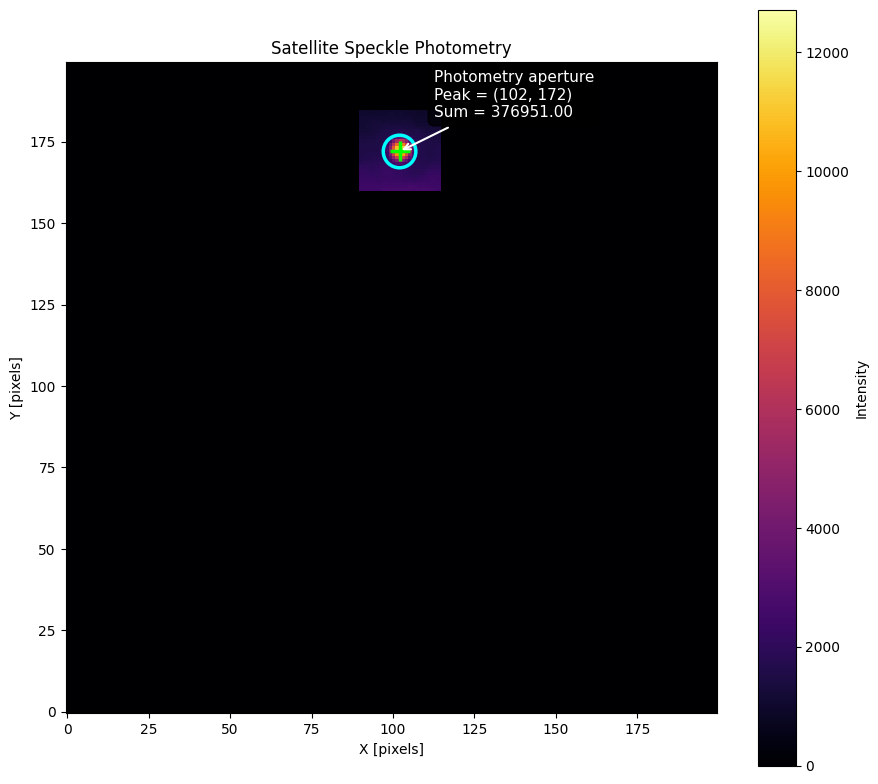

In [6]:
img_file = '/home/aosimul/noah/data/ghost_images/phase_screens_SLM/8_24/pred_5ro_20ws_coro_2026-08-25T14-15-43.791_0.tif'
center = (102, 172)
square_mask = 25
img = tiff.imread(
    glob.glob(img_file),
    key=slice(0, 9978)
)

# Median image
mean = np.median(img, axis=0)

# Apply your rectangular mask
zoom = rect_mask(mean)
#zoom = mean[150:200, 75:125]

aperture = RectangularAperture(
    positions=center,
    w=square_mask,
    h=square_mask,
)
mask = aperture.to_mask(method="center")

aperture_mask = mask.to_image(mean.shape[-2:])

# Pixels outside the rectangular annulus
zoom = mean * aperture_mask
# Find the peak
peak, coords = zoom_to_peak(zoom, radius=10)
y_peak, x_peak = coords

# Photometry aperture
r_ap = 5

tmp_apertures_sym = CircularAperture(
    positions= (x_peak, y_peak),
    r=r_ap
)

# Do photometry
peak_value = aperture_photometry(
    zoom,
    tmp_apertures_sym,
    method='center'
)['aperture_sum'][0]

print(f"Peak value of the satellite speckle: {peak_value}")


# ---------------------------------------------------------
# VISUALIZATION
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 8))

im = ax.imshow(
    zoom,
    origin='lower',
    cmap='inferno'
)

# Show the photometry aperture
tmp_apertures_sym.plot(
    ax=ax,
    color='cyan',
    lw=2.5
)

# Mark the exact peak location
ax.plot(
    x_peak,
    y_peak,
    marker='+',
    markersize=15,
    markeredgewidth=2.5,
    color='lime'
)

# Label the peak
ax.annotate(
    f'Photometry aperture\n'
    f'Peak = ({x_peak}, {y_peak})\n'
    f'Sum = {peak_value:.2f}',
    xy=(float(x_peak), float(y_peak)),
    xytext=(25, 25),
    textcoords='offset points',
    color='white',
    fontsize=11,
    bbox=dict(
        boxstyle='round,pad=0.4',
        facecolor='black',
        alpha=0.75
    ),
    arrowprops=dict(
        arrowstyle='->',
        color='white',
        lw=1.5
    )
)

ax.set_title('Satellite Speckle Photometry')
ax.set_xlabel('X [pixels]')
ax.set_ylabel('Y [pixels]')

cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Intensity')

plt.tight_layout()
plt.show()


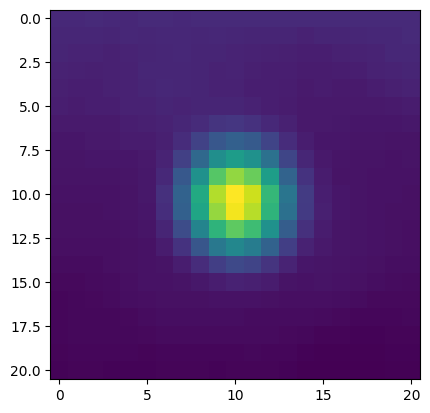

In [8]:
plt.imshow(zoom_to_peak(peak, radius=10)[0])


In [51]:
np.unravel_index(np.argmax(mean), mean.shape, order='F')

(np.int64(109), np.int64(99))

# For all

In [48]:
save_data_path = '/home/aosimul/noah/data/ghost_images/10_15_20ws/'

ori_folder = '/home/aosimul/noah/data/ghost_images/phase_screens_SLM/8_24/'


# Get all files
files = sorted(glob.glob(f"{ori_folder}*.tif"))

# Separate correctly
img_files = [
    f for f in files
    if "_coro" in os.path.basename(f) 
    and "no_coro" not in os.path.basename(f)
]

psf_files = [
    f for f in files
    if "no_coro" in os.path.basename(f)
]

# Count occurrences of each root
img_root_counts = Counter(
    os.path.basename(f).split("_coro")[0]
    for f in img_files
)

psf_root_counts = Counter(
    os.path.basename(f).split("_no_coro")[0]
    for f in psf_files
)



print(f"Science images: {len(img_files)}")
print(f"PSF images: {len(psf_files)}")

Science images: 36
PSF images: 18


In [3]:

# Running counters while saving
img_counter = Counter()
psf_counter = Counter()
DIT_psf = 29e-6
psf_count = 0
max_sat_speckle = []
norm_max_PSF = []

for i, img_file in enumerate(img_files[:]):
    

    # 2) Sort filename
    name = os.path.basename(img_file)          # int_1.0ro_10ws_no_coro_2026-07-22T11-24-21.543_0
    _, save_name, _ = reorder_name(name)  # int_10ro_10ws

    if img_root_counts[save_name] > 1:
        img_counter[save_name] += 1
        filename = f"sat_psf_{save_name}_{img_counter[save_name]}.npy"
    else:
        filename = f"sat_psf_{save_name}.npy"


    print(img_file)
    print(save_name)
    print(filename)


    satellite_speckle = satellite_psf(img_file, output_path=save_data_path, filename=filename)
    max_sat_speckle.append(np.max(satellite_speckle))
    calculate_fwhm(satellite_speckle)
    
    mod = i%2
    if mod != 1:
        # 5.1) Check if need to do psf
        psf_file = psf_files[psf_count]
        psf_img_processed, _ = run_pre_processing(img_file = ori_folder + Path(psf_file).stem, 
                            img_key = 10000, 
                            dark_file = f'{ori_folder}darks_psf',  
                            dark_key= 10000, 
                            #ref_psf=f'{ori_folder}psf_', 
                            radius = 10,
                            method = 'waffle',
                            n_satellites= 2,
                            normalisation= False
                            )
        psf_med = np.mean(psf_img_processed, axis = 0)
        fwhm = calculate_fwhm(psf_med)
        psf_count += 1
        norm_max_PSF.append(np.max(psf_med)/DIT_psf)


    

NameError: name 'img_files' is not defined

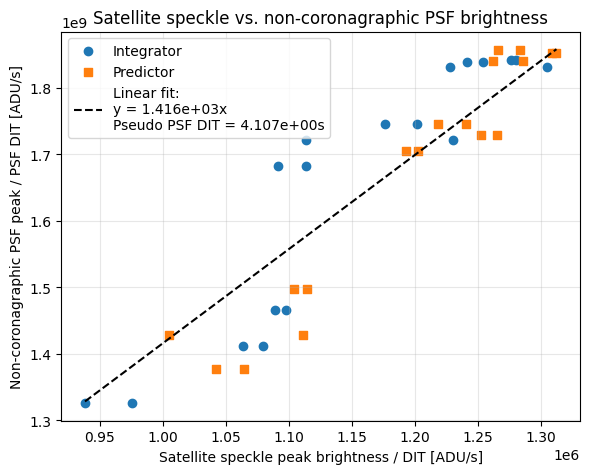

Slope = 1.416164e+03
Intercept = 0.000000e+00


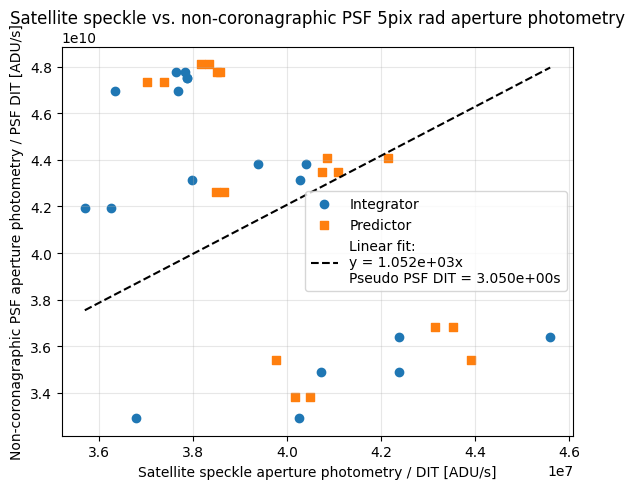

Slope = 1.051832e+03
Intercept = 0.000000e+00


In [4]:
DIT_psf = 29e-6
DIT_img = 10e-3

with open("/home/aosimul/noah/notebooks/light_intensities.json", "r") as f:
    light_intensities = json.load(f)
    

    # Extract data
    keys = list(light_intensities.keys())

    y = np.array([
        light_intensities[key]["psf"]
        for key in keys
    ]) / DIT_psf  # Convert to ADU/s

    x = np.array([
        light_intensities[key]["satellite"]
        for key in keys
    ]) / DIT_img  # Convert to ADU/s

    # Separate measured/int and predicted/pred
    is_int = np.array([key.startswith("int") for key in keys])
    is_pred = np.array([key.startswith("pred") for key in keys])

    # Linear fit to ALL points
    # slope, intercept = np.polyfit(x, y, 1)
    slope = np.sum(x * y) / np.sum(x**2)
    intercept = 0.0

    # Smooth x values for plotting the fit
    x_fit = np.linspace(x.min(), x.max(), 200)
    y_fit = slope * x_fit + intercept

    # Plot
    plt.figure(figsize=(6, 5))

    plt.scatter(
        x[is_int],
        y[is_int],
        label="Integrator",
        marker="o"
    )

    plt.scatter(
        x[is_pred],
        y[is_pred],
        label="Predictor",
        marker="s"
    )

    plt.plot(
        x_fit,
        y_fit,
        "--",
        color="black",
        label=f"Linear fit: \ny = {slope:.3e}x \nPseudo PSF DIT = {(slope*DIT_psf/DIT_img):.3e}s"
    )

    plt.ylabel("Non-coronagraphic PSF peak / PSF DIT [ADU/s]")
    plt.xlabel("Satellite speckle peak brightness / DIT [ADU/s]")
    plt.title("Satellite speckle vs. non-coronagraphic PSF brightness")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    print(f"Slope = {slope:.6e}")
    print(f"Intercept = {intercept:.6e}")

    #------
    y = np.array([
        light_intensities[key]["psf_photometry"]
        for key in keys
    ]) / DIT_psf  # Convert to ADU/s

    x = np.array([
        light_intensities[key]["satellite_photometry"]
        for key in keys
    ]) / DIT_img  # Convert to ADU/s

    # Separate measured/int and predicted/pred
    is_int = np.array([key.startswith("int") for key in keys])
    is_pred = np.array([key.startswith("pred") for key in keys])

    # Linear fit to ALL points
    # slope, intercept = np.polyfit(x, y, 1)
    slope = np.sum(x * y) / np.sum(x**2)
    intercept = 0.0

    # Smooth x values for plotting the fit
    x_fit = np.linspace(x.min(), x.max(), 200)
    y_fit = slope * x_fit + intercept

    # Plot
    plt.figure(figsize=(6, 5))

    plt.scatter(
        x[is_int],
        y[is_int],
        label="Integrator",
        marker="o"
    )

    plt.scatter(
        x[is_pred],
        y[is_pred],
        label="Predictor",
        marker="s"
    )

    plt.plot(
        x_fit,
        y_fit,
        "--",
        color="black",
        label=f"Linear fit: \ny = {slope:.3e}x \nPseudo PSF DIT = {(slope*DIT_psf/DIT_img):.3e}s"
    )

    plt.ylabel("Non-coronagraphic PSF aperture photometry / PSF DIT [ADU/s]")
    plt.xlabel("Satellite speckle aperture photometry / DIT [ADU/s]")
    plt.title("Satellite speckle vs. non-coronagraphic PSF 5pix rad aperture photometry")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    print(f"Slope = {slope:.6e}")
    print(f"Intercept = {intercept:.6e}")


In [28]:
with open("/home/aosimul/noah/notebooks/light_intensities.json", "r") as f:
    light_intensities = json.load(f)
    print(light_intensities)

{'int_10ro_10ws_1': {'psf': 42535.8359375, 'psf_photometry': 1055040.3061523438, 'satellite_photometry': 456028.5378417969, 'satellite': 10979.0}, 'int_10ro_10ws_2': {'psf': 42535.8359375, 'psf_photometry': 1055040.3061523438, 'satellite_photometry': 423769.775390625, 'satellite': 10886.0}, 'int_10ro_15ws_1': {'psf': 40960.8359375, 'psf_photometry': 1011606.0494384766, 'satellite_photometry': 407321.59375, 'satellite': 10635.0}, 'int_10ro_15ws_2': {'psf': 40960.8359375, 'psf_photometry': 1011606.0494384766, 'satellite_photometry': 423855.109375, 'satellite': 10793.0}, 'int_10ro_20ws_1': {'psf': 38457.7421875, 'psf_photometry': 954472.5952148438, 'satellite_photometry': 402471.3664550781, 'satellite': 9381.0}, 'int_10ro_20ws_2': {'psf': 38457.7421875, 'psf_photometry': 954472.5952148438, 'satellite_photometry': 367858.3310546875, 'satellite': 9757.0}, 'int_5ro_10ws_1': {'psf': 53331.23046875, 'psf_photometry': 1385466.3022460938, 'satellite_photometry': 378246.4162597656, 'satellite': 1

FWHM_x = 4.80 pix
FWHM_y = 4.86 pix
Mean FWHM = 4.83 pix 

FWHM_x = 4.05 pix
FWHM_y = 4.20 pix
Mean FWHM = 4.12 pix 



Text(0.5, 1.0, 'Satellite Speckle')

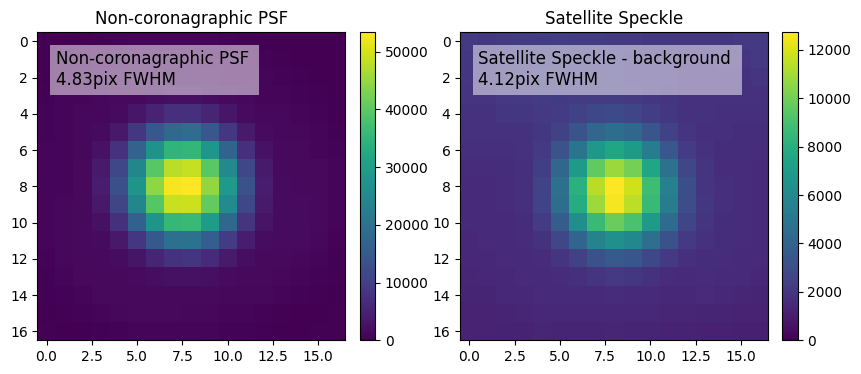

In [36]:
psf = np.load('/home/aosimul/noah/data/ghost_images/10_15_20ws/psf_int_5ro_10ws.npy')
plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.imshow(zoom_to_peak(psf, radius=8)[0], vmin = 0, vmax= np.max(zoom_to_peak(psf, radius=8)[0]))
plt.colorbar(fraction=0.046, pad=0.04)
plt.text(0.5, 0.5, f'Non-coronagraphic PSF \n{calculate_fwhm(psf):.2f}pix FWHM', ha='left', va='top', fontsize=12, bbox=dict(facecolor='white', alpha=0.5, edgecolor='none'))
plt.title('Non-coronagraphic PSF')
plt.subplot(122)
plt.imshow(zoom_to_peak(peak, radius=8)[0], vmin = 0, vmax= np.max(zoom_to_peak(peak, radius=8)[0]))
plt.colorbar(fraction=0.046, pad=0.04)
plt.text(0.5, 0.5, f'Satellite Speckle - background \n{calculate_fwhm(peak - np.median(peak[:1, :])):.2f}pix FWHM', ha='left', va='top', fontsize=12, bbox=dict(facecolor='white', alpha=0.5, edgecolor='none'))
plt.title('Satellite Speckle')

# Stacking the new images and check speckle

In [6]:
save_data_path = "/home/aosimul/noah/data/ghost_images/long_7ro_20ws"

save_analysis_path = "/home/aosimul/noah/src/pipeline_pre_ADI/results/long_7ro_20ws"
ori_folder = "/home/aosimul/noah/data/ghost_images/phase_screens_SLM/10_6/"

# geometry
radius = 55
mask_radius = 35
mask_outlier = CircularAperture((radius, radius), mask_radius).to_mask(method="center")
DIT_psf = 29e-6
DIT_img = 2.814e-3


# Get all files
files = sorted(glob.glob(f"{ori_folder}*.tif"))

# Separate correctly
img_files = [
    f
    for f in files
    if "coro" in os.path.basename(f) and "no_coro" not in os.path.basename(f)
]

psf_files = [f for f in files if "no_coro" in os.path.basename(f)]

# Count occurrences of each root
img_root_counts = Counter(reorder_name(os.path.basename(f))[1] for f in img_files)

psf_root_counts = Counter(reorder_name(os.path.basename(f))[1] for f in psf_files)

# Running counters while saving
img_counter = Counter()
psf_counter = Counter()

print(f"Science images: {len(img_files)}")
print(f"PSF images: {len(psf_files)}")

Science images: 48
PSF images: 0


In [ ]:
for i, img_file in enumerate(img_files[:]):

    # 2) Sort filename
    name = os.path.basename(
        img_file
    )  # int_1.0ro_10ws_no_coro_2026-07-22T11-24-21.543_0
    _, save_name, _ = reorder_name(name)  # int_10ro_10ws

    if img_root_counts[save_name] > 1:
        img_counter[save_name] += 1
        filename = f"{save_name}_{img_counter[save_name]}.npy"
    else:
        filename = f"{save_name}.npy"

    print(img_file)
    print(save_name)
    print(filename)


Counter({'int_7ro_20ws_key1': 8,
         'int_7ro_20ws_key24': 8,
         'int_7ro_20ws_key32': 8,
         'pred_7ro_20ws_key1': 8,
         'pred_7ro_20ws_key24': 8,
         'pred_7ro_20ws_key32': 8})

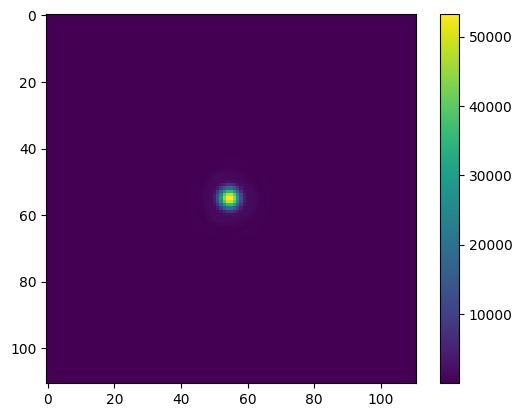

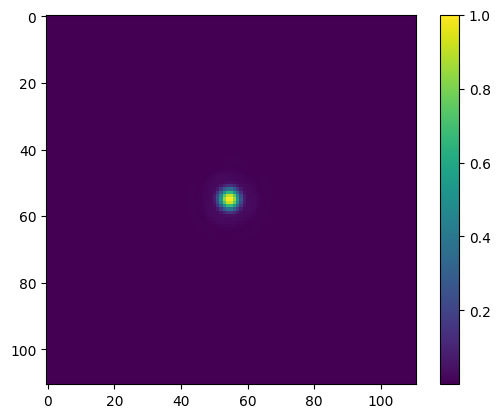

In [26]:
img = np.load('/home/aosimul/noah/data/ghost_images/10_15_20ws/psf_int_5ro_10ws.npy')
plt.imshow(img)
plt.colorbar()
plt.show()
plt.imshow(img/np.max(img))
plt.colorbar()
plt.show()
np.save('/home/aosimul/noah/data/ghost_images/10_15_20ws/master_psf.npy', img/np.max(img))

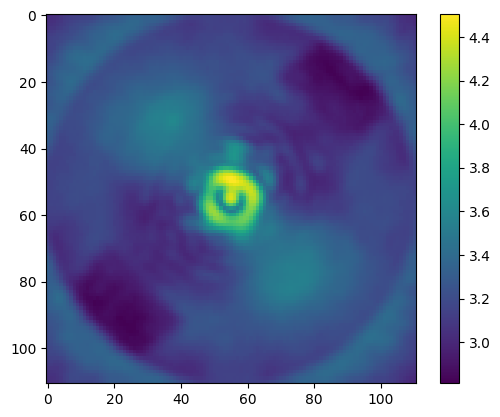

In [12]:
stack = (np.load('/home/aosimul/noah/data/ghost_images/long_7ro_20ws/int_7ro_20ws_1key_1.npy'))
mean = np.mean(stack, axis = (0))
plt.imshow(np.log10(mean))
plt.colorbar()

In [22]:
with pd.HDFStore(
    f"/home/aosimul/noah/src/pipeline_pre_ADI/results/long_7ro_20ws/raw_contrast.h5"
) as store:
    keys = store.keys()
    old_keys = [k for k in keys if "key" not in k]
    print(f"Old keys: {old_keys}")
    store.remove('int_7ro_20ws_1key')
    # for old_key in old_keys:
    #     store.remove(old_key)

Old keys: []


['/int_7ro_20ws_1key_1', '/int_7ro_20ws_1key_2', '/int_7ro_20ws_1key_3', '/int_7ro_20ws_1key_4', '/int_7ro_20ws_1key_5', '/int_7ro_20ws_1key_6', '/int_7ro_20ws_1key_7', '/int_7ro_20ws_1key_8', '/int_7ro_20ws_24key_1', '/int_7ro_20ws_24key_2', '/int_7ro_20ws_24key_3', '/int_7ro_20ws_24key_4', '/int_7ro_20ws_24key_5', '/int_7ro_20ws_24key_6', '/int_7ro_20ws_24key_7', '/int_7ro_20ws_24key_8', '/int_7ro_20ws_32key_1', '/int_7ro_20ws_32key_2', '/int_7ro_20ws_32key_3', '/int_7ro_20ws_32key_4', '/int_7ro_20ws_32key_5', '/int_7ro_20ws_32key_6', '/int_7ro_20ws_32key_7', '/int_7ro_20ws_32key_8', '/pred_7ro_20ws_1key_1', '/pred_7ro_20ws_1key_2', '/pred_7ro_20ws_1key_3', '/pred_7ro_20ws_1key_4', '/pred_7ro_20ws_1key_5', '/pred_7ro_20ws_1key_6', '/pred_7ro_20ws_1key_7', '/pred_7ro_20ws_1key_8', '/pred_7ro_20ws_24key_1', '/pred_7ro_20ws_24key_2', '/pred_7ro_20ws_24key_3', '/pred_7ro_20ws_24key_4', '/pred_7ro_20ws_24key_5', '/pred_7ro_20ws_24key_6', '/pred_7ro_20ws_24key_7', '/pred_7ro_20ws_24key_8',

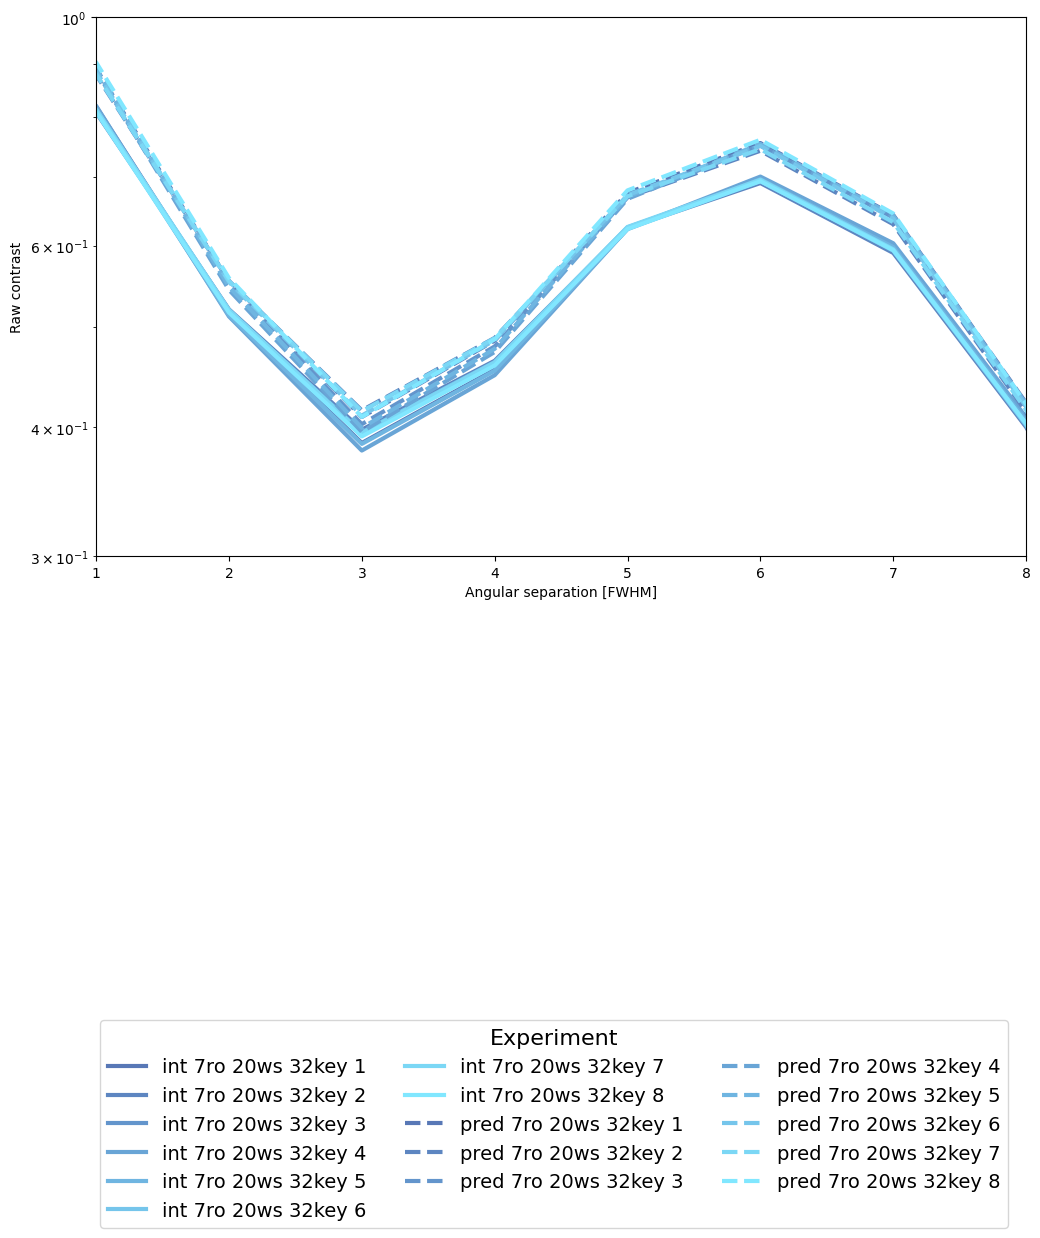

In [39]:
with pd.HDFStore(
    f"/home/aosimul/noah/src/pipeline_pre_ADI/results/long_7ro_20ws/raw_contrast.h5"
) as store:

    fig, ax = plt.subplots(figsize=(12, 7))
    gs0 = fig.add_gridspec(1, 1)
    # color_map = plt.cm.get_cmap('inferno')   # seaborn-style colormap available in mpl
    # colors = [color_map(int(i)) for i in np.round(np.linspace(0, 250, len(store.keys())))]
    color_map = plt.colormaps["tab20c"]
    colors = color_map(np.linspace(0, 1, len(store)))
    seq = "managua"
    reds = plt.colormaps[seq]
    blues = plt.colormaps[seq]
    greens = plt.colormaps[seq]

    int_keys = [k for k in store.keys() if "int" in k]
    pred_keys = [k for k in store.keys() if "pred" in k]

    red_colors = dict(zip(int_keys, reds(np.linspace(0.2, 1, len(int_keys)))))
    blue_colors = dict(zip(pred_keys, blues(np.linspace(0.2, 1, len(pred_keys)))))

    # Then inside the loop:

    ordered_keys = int_keys + pred_keys 

    for key in store.keys():
        if "7ro_20ws_32key" not in key:
            continue

        df = store[key]
        line_color = (
            red_colors[key]
            if "int" in key
            else blue_colors[key]
        )

        mark = "-" if "int" in key else "--" 

        label = key.strip("/").replace("_", " ")
        ax.semilogy(
            df.index.get_level_values("pixel_rad"),
            df["raw_contrast"] * 2.814e-3 / 29e-6,
            lw=3,
            color=line_color,  # colors[i],
            ls=mark,
            label=label,
        )

    leg1 = fig.legend(
        fontsize=14,
        loc="lower left",
        bbox_to_anchor=(0.12, -(0.018 * len(store.keys()))),
        ncol=3,
        title="Experiment",
        title_fontsize=16,
    )
    ax.set_xlim(1, 8)
    ax.set_ylim(bottom = 3e-1, top = 1)
    ax.set_xlabel("Angular separation [FWHM]")
    ax.set_ylabel("Raw contrast")
    print(store.keys())

In [45]:
folder = Path("/home/aosimul/noah/data/ghost_images/long_7ro_20ws")

# Find all .npy files
files = list(folder.glob("*.npy"))

# Group files by their prefix before _1.npy, _2.npy, etc.
groups = {}

for file in files:
    match = re.fullmatch(r"(.+)_([1-8])", file.stem)
    if match:
        prefix, number = match.groups()
        groups.setdefault(prefix, {})[int(number)] = file

# Stack groups 1–4 and 5–8
for prefix, numbered_files in groups.items():
    for suffix, numbers in [
        ("1-4", range(1, 5)),
        ("5-8", range(5, 9)),
    ]:
        if not all(n in numbered_files for n in numbers):
            print(f"Skipping {prefix}_{suffix}: missing files")
            continue

        print(f"Stacking {prefix}_{suffix}:")
        print([numbered_files[n].name for n in numbers])


        arrays = [
            np.load(numbered_files[n])
            for n in numbers
        ]

        stacked = np.concatenate(arrays, axis=0)

        output_file = folder / f"{prefix}_{suffix}.npy"
        np.save(output_file, stacked)

        print(f"Saved {output_file}: shape {stacked.shape}")

Stacking int_7ro_20ws_1key_1-4:
['int_7ro_20ws_1key_1.npy', 'int_7ro_20ws_1key_2.npy', 'int_7ro_20ws_1key_3.npy', 'int_7ro_20ws_1key_4.npy']
Saved /home/aosimul/noah/data/ghost_images/long_7ro_20ws/int_7ro_20ws_1key_1-4.npy: shape (42139, 111, 111)
Stacking int_7ro_20ws_1key_5-8:
['int_7ro_20ws_1key_5.npy', 'int_7ro_20ws_1key_6.npy', 'int_7ro_20ws_1key_7.npy', 'int_7ro_20ws_1key_8.npy']
Saved /home/aosimul/noah/data/ghost_images/long_7ro_20ws/int_7ro_20ws_1key_5-8.npy: shape (42203, 111, 111)
Stacking int_7ro_20ws_24key_1-4:
['int_7ro_20ws_24key_1.npy', 'int_7ro_20ws_24key_2.npy', 'int_7ro_20ws_24key_3.npy', 'int_7ro_20ws_24key_4.npy']
Saved /home/aosimul/noah/data/ghost_images/long_7ro_20ws/int_7ro_20ws_24key_1-4.npy: shape (42021, 111, 111)
Stacking int_7ro_20ws_24key_5-8:
['int_7ro_20ws_24key_5.npy', 'int_7ro_20ws_24key_6.npy', 'int_7ro_20ws_24key_7.npy', 'int_7ro_20ws_24key_8.npy']
Saved /home/aosimul/noah/data/ghost_images/long_7ro_20ws/int_7ro_20ws_24key_5-8.npy: shape (41954, 11


Integrator outliers:
  int_7ro_20ws_24key_8: 1.102099e+06 ADU/s

Integrator:
  Number of measurements = 24
  Mean                   = 1.219084e+06 ADU/s
  Standard deviation     = 3.200477e+04 ADU/s
  Outliers               = 1

Predictor outliers:
  pred_7ro_20ws_32key_8: 1.637586e+06 ADU/s

Predictor:
  Number of measurements = 24
  Mean                   = 1.448864e+06 ADU/s
  Standard deviation     = 5.368287e+04 ADU/s
  Outliers               = 1


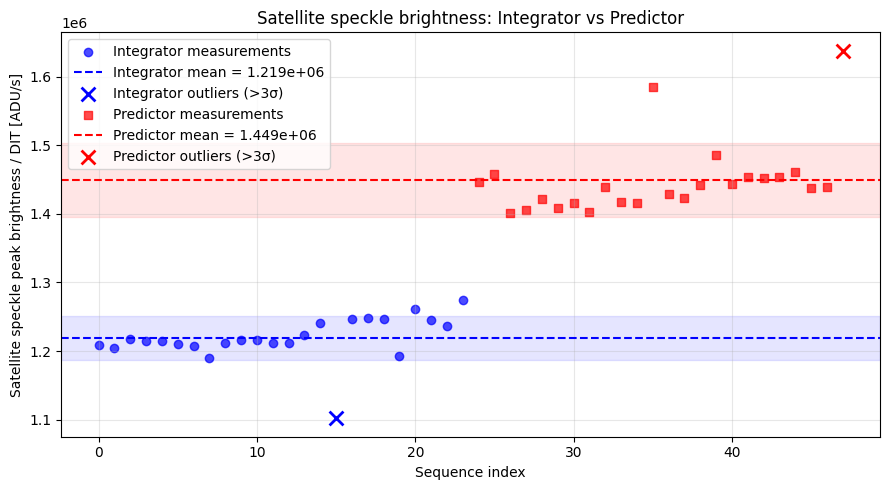

In [52]:

DIT_img = 2.814e-3

with open(
    "/home/aosimul/noah/src/pipeline_pre_ADI/results/long_7ro_20ws/light_intensities.json",
    "r",
) as f:
    light_intensities = json.load(f)

# Extract data
keys = list(light_intensities.keys())

y = np.array([
    light_intensities[key]["satellite"]
    for key in keys
]) / DIT_img  # Convert to ADU/s

x = np.arange(len(keys))

# Separate Integrator and Predictor
is_int = np.array([key.startswith("int") for key in keys])
is_pred = np.array([key.startswith("pred") for key in keys])

groups = {
    "Integrator": (is_int, "o"),
    "Predictor": (is_pred, "s"),
}
colors = ["blue", "red"]
plt.figure(figsize=(9, 5))

for name, (mask, marker) in groups.items():
    x_group = x[mask]
    y_group = y[mask]
    keys_group = np.array(keys)[mask]

    if len(y_group) == 0:
        continue

    # Mean and standard deviation
    mean = np.mean(y_group)
    std = np.std(y_group)

    # Outliers: more than 3 standard deviations from the mean
    outlier_mask = np.abs(y_group - mean) > 3 * std

    # Plot individual measurements
    plt.scatter(
        x_group[~outlier_mask],
        y_group[~outlier_mask],
        marker=marker,
        label=f"{name} measurements",
        alpha=0.7,
        color=colors[0] if name == "Integrator" else colors[1],
        zorder = 1,
    )

    # Plot mean and ±1 standard deviation
    plt.axhline(
        mean,
        linestyle="--",
        label=f"{name} mean = {mean:.3e}",
        color=colors[0] if name == "Integrator" else colors[1]
    )

    plt.axhspan(
        mean - std,
        mean + std,
        alpha=0.1,
        color=colors[0] if name == "Integrator" else colors[1]
    )

    # Highlight outliers
    if np.any(outlier_mask):
        plt.scatter(
            x_group[outlier_mask],
            y_group[outlier_mask],
            marker="x",
            color= colors[0] if name == "Integrator" else colors[1],
            s=100,
            linewidths=2,
            label=f"{name} outliers (>3σ)",
            zorder=5,
        )

        print(f"\n{name} outliers:")
        for key, value in zip(
            keys_group[outlier_mask],
            y_group[outlier_mask],
        ):
            print(f"  {key}: {value:.6e} ADU/s")

    print(f"\n{name}:")
    print(f"  Number of measurements = {len(y_group)}")
    print(f"  Mean                   = {mean:.6e} ADU/s")
    print(f"  Standard deviation     = {std:.6e} ADU/s")
    print(f"  Outliers               = {np.sum(outlier_mask)}")

plt.xlabel("Sequence index")
plt.ylabel("Satellite speckle peak brightness / DIT [ADU/s]")
plt.title("Satellite speckle brightness: Integrator vs Predictor")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
